In [24]:
import pandas as pd

df_test = pd.read_csv("test_data.csv")

df_test.head()

,datapointID,textA,textB
0,120,o utse airs eaien eii llin cri.,NaN
1,1168,e str er's ga ii hie ied al wi e aad en swih e...,NaN
2,796,"den diin eipri skis, eie ren ers ie taend ie c...",NaN
3,114,he e kekcleazologuclea nem e hejen eleajecleaz...,NaN
4,989,licrhcrevbe coheleaenlicr gleaoup crhiileaed i...,NaN


In [25]:
df_1 = df_test[df_test.textB.isna() == False]
df_2 = df_test[df_test.textB.isna() == True]

df_1.head()

,datapointID,textA,textB
7,1553,"unec, tler.","evenlicrcr cruch iicr feiicrlicrcr, biinquelic..."
8,1537,1688 1792 (giri seil enc heil).,"folealicr longueubel, bubellicr fleaom 1695 li..."
12,1439,"qia upied, xed evi.",e umpee e se j uesif arad unar pa. eeeq ued ue...
17,1322,crpolealicrcr cullicruleae crpolealicr concrbe...,"e boleagucleaecleagucleaecleacleaegeguclea"" be..."
33,1348,crpolealicrcr leiiguecr oleagiincrevbeiilicrbe...,e thi umpe iair uer e pai ind ins ire stad lid...


In [26]:
import re

def preprocess(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df_1.loc[:, "textA"] = df_1.loc[:, "textA"].apply(preprocess)
df_1.loc[:, "textB"] = df_1.loc[:, "textB"].apply(preprocess)
df_2.loc[:, "textA"] = df_2.loc[:, "textA"].apply(preprocess)

df_1.head()

,datapointID,textA,textB
7,1553,unec tler,evenlicrcr cruch iicr feiicrlicrcr biinquelicr...
8,1537,giri seil enc heil,folealicr longueubel bubellicr fleaom licro bh...
12,1439,qia upied xed evi,e umpee e se j uesif arad unar pa eeeq ued uer...
17,1322,crpolealicrcr cullicruleae crpolealicr concrbe...,e boleagucleaecleagucleaecleacleaegeguclea bef...
33,1348,crpolealicrcr leiiguecr oleagiincrevbeiilicrbe...,e thi umpe iair uer e pai ind ins ire stad lid...


In [27]:
import numpy as np
import string

alphabet = list(string.ascii_lowercase)

def char_freq(text):
    counts = np.zeros(len(alphabet))
    total = 0
    for c in text:
        if c in alphabet:
            idx = ord(c) - ord('a')
            counts[idx] += 1
            total += 1
    if total > 0:
        counts /= total
    return counts


X_1a = np.vstack(df_1.textA.apply(char_freq))
X_1b = np.vstack(df_1.textB.apply(char_freq))
X_2 = np.vstack(df_2.textA.apply(char_freq))

all_texts = np.vstack([X_1a, X_1b, X_2])

X_1a

array([[0.        , 0.        , 0.125     , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.06666667, ..., 0.        , 0.        ,
        0.        ],
       [0.07142857, 0.        , 0.        , ..., 0.07142857, 0.        ,
        0.        ],
       ...,
       [0.13740458, 0.        , 0.02290076, ..., 0.        , 0.        ,
        0.        ],
       [0.04895105, 0.04895105, 0.11188811, ..., 0.        , 0.        ,
        0.        ],
       [0.06024096, 0.02409639, 0.12048193, ..., 0.        , 0.        ,
        0.        ]])

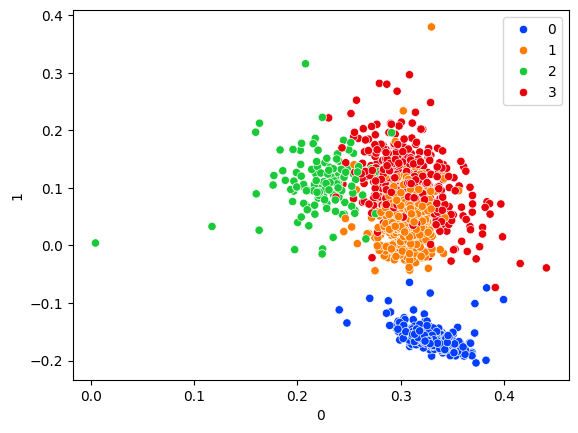

In [28]:
from scipy.sparse import vstack
all_texts = vstack([X_1a, X_1b, X_2])

from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

svd = TruncatedSVD(n_components=2)
texts_red = pd.DataFrame(svd.fit_transform(all_texts))

kmeans = KMeans(n_clusters=4, random_state=42)
labels = kmeans.fit_predict(all_texts)

sns.scatterplot(x=texts_red[0], y=texts_red[1], hue=labels, palette='bright')
plt.show()

In [99]:
preds_1a = labels[:len(df_1)]
preds_1b = labels[len(df_1):len(df_1)*2]
preds_2 = labels[len(df_1)*2:]

In [100]:
terms = vect.get_feature_names_out()

for i in range(4):
    center = kmeans.cluster_centers_[i]
    top = center.argsort()[-10:]
    print(i, [terms[t] for t in top])

0 [' a at', ' a aer', ' a a', ' a at ', ' a ade', ' a cer', ' a aa', ' a ', ' a ap', ' a ad']
1 [' a ae', ' a ', ' a at', ' a at ', ' a a', ' a aur', ' a ap', ' a aa', ' a ae ', ' a ad']
2 [' a at', ' a aer', ' a ', ' a ap', ' a cer', ' a ce', ' a c', ' a aur', ' a ad', ' a ae ']
3 [' a cer', ' a ap', ' a at', ' a aa ', ' a ce', ' a aur', ' a c', ' a ', ' a ae ', ' a ad']


In [101]:
mapping = {
    0: "Hungeleabeen",
    1: "Englcrevbeh",
    2: "Hure",
    3: "En Gli"
}

In [102]:
answer = (preds_1a == preds_1b)

subtask1 = pd.DataFrame({
    "datapointID": df_1.datapointID,
    "subtaskID": 1,
    "answer": answer
})

subtask1["answer"] = subtask1["answer"].astype(str).str.lower()

subtask1.answer.value_counts()

answer
false    246
true     104
Name: count, dtype: int64

In [103]:
preds_2 = pd.Series(preds_2, index=df_2.index).map(mapping)

subtask2 = pd.DataFrame({
    "datapointID": df_2.datapointID,
    "subtaskID": 2,
    "answer": preds_2
})

subtask2.head()

,datapointID,subtaskID,answer
0,120,2,En Gli
1,1168,2,En Gli
2,796,2,En Gli
3,114,2,Hungeleabeen
4,989,2,Englcrevbeh


In [104]:
submission = pd.concat([subtask1, subtask2])
submission

,datapointID,subtaskID,answer
7,1553,1,false
8,1537,1,true
12,1439,1,true
17,1322,1,false
33,1348,1,false
...,...,...,...
1582,782,2,En Gli
1583,416,2,Hungeleabeen
1584,760,2,En Gli
1585,656,2,Englcrevbeh


In [105]:
submission.to_csv("submission.csv", index=False)